# Covariance structures and diagnostics

Two related themes, both about the random-effects covariance matrix and whether its estimate
can be trusted:

**(a) Structured covariance matrices (new in lme4 2.x).** A random-effects term can be
tagged with a covariance structure:

| term | covariance matrix of the random effects | parameters |
|---|---|---|
| `(x | g)` = `us(x | g)` | unstructured (general positive semi-definite) | $q(q+1)/2$ |
| `diag(x | g)` | diagonal (independent effects; `hom=TRUE`: equal variances) | $q$ (1) |
| `cs(x | g)` | compound symmetry: one common correlation $\rho$ (`hom=TRUE`: also equal variances) | $q+1$ (2) |
| `ar1(x | g)` | first-order autoregressive: correlation $\rho^{|i-j|}$ (homogeneous by default) | 2 ($q+1$) |

We compare them by AIC, look at how `VarCorr` prints them, and at the difference between
`getME(m, "par")` (the parameters the optimizer works on: standard deviations relative to
$\sigma$ and correlations) and `getME(m, "theta")` (the elements of the lower Cholesky factor
of the relative covariance matrix, which is what the penalized least squares machinery uses).

**(b) Diagnostics and troubleshooting.** Singular fits (`isSingular`, and the new
`rePCA()`), convergence warnings (the derivative checks, tighter tolerances, restarts,
`allFit` across optimizers), badly scaled predictors (`check.scaleX` and `autoscale`),
per-group `lmList` fits as an exploratory tool, deletion influence (`influence`, Cook's
distance, `hatvalues`) and residual checks.

## Source

* lme4 2.x covariance structures: [`?Covariance-class`](https://github.com/lme4/lme4/blob/master/man/Covariance-class.Rd),
  the vignette [`covariance_structures`](https://github.com/lme4/lme4/blob/master/vignettes/covariance_structures.Rmd),
  the tests [`tests/testthat/test-covariance_structures.R`](https://github.com/lme4/lme4/blob/master/tests/testthat/test-covariance_structures.R)
  and the NEWS for 2.0-0 (local copies in `upstream/lme4/`);
* diagnostics: [`?isSingular`](https://github.com/lme4/lme4/blob/master/man/isSingular.Rd),
  [`?rePCA`](https://github.com/lme4/lme4/blob/master/man/rePCA.Rd),
  [`?convergence`](https://github.com/lme4/lme4/blob/master/man/convergence.Rd),
  [`?allFit`](https://github.com/lme4/lme4/blob/master/man/allFit.Rd),
  the vignette [`autoscale`](https://github.com/lme4/lme4/blob/master/vignettes/autoscale.Rmd),
  [`?lmList`](https://github.com/lme4/lme4/blob/master/man/lmList.Rd),
  [`?influence.merMod`](https://github.com/lme4/lme4/blob/master/man/influence.merMod.Rd),
  [`?hatvalues.merMod`](https://github.com/lme4/lme4/blob/master/man/hatvalues.merMod.Rd).

The R code (the full reference script is `examples/r/08_covariance_structures_and_diagnostics.R`):

```r
library(lme4)
## (a) structured covariances
fm1      <- lmer(Reaction ~ Days + (Days | Subject), sleepstudy, REML = FALSE)
fm1.us   <- lmer(Reaction ~ Days + us(Days | Subject), sleepstudy, REML = FALSE)
fm1.cs   <- lmer(Reaction ~ Days + cs(Days | Subject), sleepstudy, REML = FALSE)
fm1.diag <- lmer(Reaction ~ Days + diag(Days | Subject), sleepstudy, REML = FALSE)
anova(fm1.diag, fm1.cs, fm1.us)

fm1.cs <- lmer(Reaction ~ Days + cs(1 + Days | Subject), sleepstudy)   # vignette
getReCovs(fm1.cs); getME(fm1.cs, "par"); getME(fm1.cs, "theta"); VarCorr(fm1.cs)$Subject

m_cs_hom <- lmer(Reaction ~ Days + cs(0 + factor(Days) | Subject, hom = TRUE), sleepstudy, REML = FALSE)
m_cs     <- lmer(Reaction ~ Days + cs(0 + factor(Days) | Subject), sleepstudy, REML = FALSE)
m_ar1    <- lmer(Reaction ~ Days + ar1(0 + factor(Days) | Subject), sleepstudy, REML = FALSE)
AIC(m_cs_hom, m_cs, m_ar1, fm1)

## (b) singular fits
lmer(Yield ~ 1 + (1 | Batch), Dyestuff2)                        # boundary (singular) fit
mc <- lmer(angle ~ recipe + temp + (recipe | replicate), cake)  # singular, no zero variance
isSingular(mc); rePCA(mc); summary(rePCA(mc))

## convergence (?convergence)
fm1 <- lmer(Reaction ~ Days + (Days | Subject), sleepstudy)
fm1@optinfo$derivs; Matrix::rcond(fm1@optinfo$derivs$Hessian)
fm1.tol <- update(fm1, control = lmerControl(optCtrl = list(xtol_abs = 1e-8, ftol_abs = 1e-8)))
fm1.CS  <- update(fm1, data = transform(sleepstudy, Days = scale(Days)))
fm1.restart <- update(fm1, start = getME(fm1, "theta"))
lmer(Reaction ~ Days + I(Days^2) + (Days + I(Days^2) | Subject), sleepstudy)  # convergence warning

## rescaling (vignette("autoscale"))
set.seed(1); sleepstudy$var1 <- runif(nrow(sleepstudy), 1e6, 1e7)
fit1 <- lmer(Reaction ~ var1 + Days + (Days | Subject), sleepstudy)          # check.scaleX warning
fit2 <- lmer(Reaction ~ var1 + Days + (Days | Subject), sleepstudy,
             control = lmerControl(autoscale = TRUE))

## allFit
gm1 <- glmer(cbind(incidence, size - incidence) ~ period + (1 | herd), data = cbpp, family = binomial)
ss <- summary(allFit(gm1)); ss$which.OK; ss$llik; ss$fixef; ss$theta

## lmList, influence, residuals
fm.plm <- lmList(Reaction ~ Days | Subject, sleepstudy); coef(fm.plm); confint(fm.plm)
inf_fm1 <- influence(fm1, "Subject"); cooks.distance(inf_fm1); dfbeta(inf_fm1); dfbetas(inf_fm1)
hatvalues(fm1); cooks.distance(fm1); residuals(fm1, type = "pearson", scaled = TRUE)
```

In [1]:
import json
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.testing import assert_allclose, assert_array_equal

import lme4
from lme4 import (lmer, glmer, binomial, load_dataset, getME, VarCorr, isSingular, rePCA,
                  lmerControl, allFit, lmList, influence, anova)
from lme4.plots import plot_merMod, qqmath_merMod

with open("reference/08_covariance_structures_and_diagnostics.json") as f:
    ref = json.load(f)
sleepstudy = load_dataset("sleepstudy")


def check_model(m, r, rtol=1e-6, rtol_ll=1e-8, varcorr=True, atol=1e-6):
    """compare a fit with the R statistics stored by mstats() in the R script"""
    assert_allclose(float(m.logLik()), r["logLik"], rtol=rtol_ll)
    assert m.logLik().df == r["df"]
    assert_allclose(m.AIC(), r["AIC"], rtol=rtol_ll)
    assert_allclose(m.fixef().values, r["fixef"], rtol=rtol, atol=1e-8)
    par = getME(m, "par")
    assert list(par.index) == list(np.atleast_1d(r["par_names"]))
    assert_allclose(par.values, r["par"], rtol=rtol, atol=atol)
    assert_allclose(getME(m, "theta").values, r["theta"], rtol=rtol, atol=atol)
    assert_allclose(m.sigma(), r["sigma"], rtol=rtol)
    assert bool(m.isSingular()) == r["singular"]
    if varcorr:
        same_printout(str(VarCorr(m)).splitlines(), r["VarCorr"], rtol)


def same_printout(ours, theirs, rtol=0.0):
    """compare printed output line by line.  With rtol=0 the text must be identical except
    that printed numbers may differ by one unit in their last digit (rounding of nearly
    equal values).  With rtol > 0 (estimates that legitimately differ slightly) the lines
    are compared token by token: words identical, numbers within rtol or one printed unit,
    since R chooses the number of printed digits from the values themselves."""
    num = re.compile(r"-?\d+\.\d+")
    assert len(ours) == len(theirs), "\n".join(ours)
    for a, b in zip(ours, theirs):
        if rtol == 0:
            assert num.sub("#", a).rstrip() == num.sub("#", b).rstrip(), f"{a!r} != {b!r}"
        ta, tb = a.split(), b.split()
        assert len(ta) == len(tb), f"{a!r} != {b!r}"
        for x, y in zip(ta, tb):
            if num.fullmatch(y) and num.fullmatch(x):
                unit = 10.0 ** -min(len(x.split(".")[1]), len(y.split(".")[1]))
                assert abs(float(x) - float(y)) <= max(unit * 1.0001, rtol * abs(float(y))), \
                    f"{a!r} != {b!r}"
            else:
                assert x == y, f"{a!r} != {b!r}"

# Part (a): structured covariance matrices

## 1. One model, four covariance structures

The random intercept and slope of `Reaction ~ Days + (Days | Subject)` have a $2\times 2$
covariance matrix. `us()` is the default unstructured matrix (so `fm1` and `fm1_us` are the
same model), `cs()` with two effects has one correlation and two variances, so it is
also unstructured here — just a different parametrization — and `diag()` forces the correlation to zero.

In [2]:
fm1      = lmer("Reaction ~ Days + (Days | Subject)", sleepstudy, REML=False)
fm1_us   = lmer("Reaction ~ Days + us(Days | Subject)", sleepstudy, REML=False)
fm1_cs   = lmer("Reaction ~ Days + cs(Days | Subject)", sleepstudy, REML=False)
fm1_diag = lmer("Reaction ~ Days + diag(Days | Subject)", sleepstudy, REML=False)
for name, m in [("us", fm1_us), ("cs", fm1_cs), ("diag", fm1_diag)]:
    print(f"--- {name}: logLik = {float(m.logLik()):.6f}")
    print(VarCorr(m))

--- us: logLik = -875.969672
 Groups   Name        Std.Dev. Corr  
 Subject  (Intercept) 23.7805        
          Days         5.7168  0.081 
 Residual             25.5918        
--- cs: logLik = -875.969672
 Groups   Name        Std.Dev. Corr      
 Subject  (Intercept) 23.7807  0.081 (cs)
          Days         5.7168            
 Residual             25.5918            
--- diag: logLik = -876.001628
 Groups   Name        Std.Dev.
 Subject  (Intercept) 24.1714 
          Days         5.7994 
 Residual             25.5561 


`VarCorr` marks a structured term in the correlation column: `0.081 (cs)` is the single
common correlation. Likelihood ratio tests / AIC (`anova` refits nothing here, the models
are already ML fits):

In [3]:
anova(fm1_diag, fm1_cs, fm1_us, model_names=["fm1.diag", "fm1.cs", "fm1.us"])

,npar,AIC,BIC,logLik,-2*log(L),Chisq,Df,Pr(>Chisq)
fm1.diag,5,1762.003255,1777.968039,-876.001628,1752.003255,NaN,NaN,NaN
fm1.cs,6,1763.939344,1783.097086,-875.969672,1751.939344,6.391067e-02,1.0,0.800418
fm1.us,6,1763.939344,1783.097086,-875.969672,1751.939344,2.922889e-09,0.0,NaN


### `par` versus `theta`

For `cs()` the optimizer works on `par` = (relative standard deviations, $\rho$), while the
model matrices use `theta`, the lower-triangular Cholesky factor $\Lambda$ of the relative
covariance matrix (column-wise). For `us()` the two coincide.

In [4]:
pd.DataFrame({"par (us)": getME(fm1_us, "par").values, "theta (us)": getME(fm1_us, "theta").values,
              "par (cs)": getME(fm1_cs, "par").values, "theta (cs)": getME(fm1_cs, "theta").values},
             index=["1", "2", "3"])

,par (us),theta (us),par (cs),theta (cs)
1,0.929221,0.929221,0.929231,0.929231
2,0.018168,0.018168,0.223386,0.018169
3,0.222645,0.222645,0.081336,0.222646


In [5]:
# theta is the Cholesky factor of the covariance matrix implied by par:
sd1, sd2, rho = getME(fm1_cs, "par")
S = np.array([[sd1**2, rho * sd1 * sd2], [rho * sd1 * sd2, sd2**2]])
L = np.linalg.cholesky(S)
assert_allclose([L[0, 0], L[1, 0], L[1, 1]], getME(fm1_cs, "theta").values, rtol=1e-10)
# and sigma^2 * S is the covariance matrix reported by VarCorr
assert_allclose(fm1_cs.sigma()**2 * S, np.asarray(VarCorr(fm1_cs)["Subject"]), rtol=1e-10)
L

array([[0.92923147, 0.        ],
       [0.01816922, 0.22264565]])

### Check against R

The default optimizer `nloptwrap` stops when the deviance changes by less than
`ftol_abs = 1e-6`; near the optimum the deviance is quadratic, so the parameters are only
determined to about $\sqrt{10^{-6}}$ relative to their curvature. The log-likelihoods agree
to 1e-8 or better, the estimates to about 1e-4 (in R itself, `fm1` and `fm1.us` agree only to
that level for the same reason).

In [6]:
for m, key in [(fm1, "fm1"), (fm1_us, "fm1_us"), (fm1_cs, "fm1_cs"), (fm1_diag, "fm1_diag")]:
    check_model(m, ref[key], rtol=2e-4)
print("us/cs/diag fits agree with R")

us/cs/diag fits agree with R


## 2. The vignette example: `cs(1 + Days | Subject)` (REML)

`getReCovs()` returns the covariance objects themselves (R prints the S4 slots `hom`,
`nc`, `par`).

In [7]:
fm1_csR = lmer("Reaction ~ Days + cs(1 + Days | Subject)", sleepstudy)
print(fm1_csR.getReCovs())
print(getME(fm1_csR, "par"))
print(getME(fm1_csR, "theta"))
print(fm1_csR.summary())

[Covariance.cs(nc=2, hom=False, par=[0.96674055 0.23140894 0.06555015])]
Subject.(Intercept)    0.966741
Subject.Days           0.231409
Subject.rho            0.065550
dtype: float64
Subject.(Intercept)         0.966741
Subject.Days.(Intercept)    0.015169
Subject.Days                0.230911
dtype: float64
Linear mixed model fit by REML ['lmerMod']
Formula: Reaction ~ Days + cs(1 + Days | Subject)
   Data: sleepstudy

REML criterion at convergence: 1743.6

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.9536 -0.4634  0.0231  0.4634  5.1793 

Random effects:
 Groups   Name        Variance Std.Dev. Corr     
 Subject  (Intercept) 612.10   24.741   0.07 (cs)
          Days         35.07    5.922            
 Residual             654.94   25.592            
Number of obs: 180, groups:  Subject, 18

Fixed effects:
            Estimate Std. Error t value
(Intercept)  251.405      6.825  36.838
Days          10.467      1.546   6.771

Correlation of Fixed Effects:
     (Intr)

### Check against R

With two effects `cs()` is just a reparametrization of `us()`, so its optimum must be the
unstructured one. The likelihood is very flat in the correlation $\rho$ (its estimate, 0.066,
has a huge standard error): Python's `nloptwrap` run ends at the `us()` optimum to 6 digits,
R's stops slightly earlier (its $\rho$ differs in the 3rd digit while the REML criterion agrees
to 1e-9). The parameters are therefore compared at 2e-3; the printed summary must be identical
up to rounding in the last printed digit.

In [8]:
check_model(fm1_csR, ref["vig_cs"], rtol=2e-3)
fm1_usR = lmer("Reaction ~ Days + (Days | Subject)", sleepstudy)
assert_allclose(getME(fm1_csR, "theta").values, getME(fm1_usR, "theta").values, rtol=1e-4)
assert_allclose(fm1_csR.getReCovs()[0].par, ref["vig_cs"]["par"], rtol=2e-3)
# the printed summary, line by line
same_printout(str(fm1_csR.summary()).splitlines(), ref["vig_cs_summary"], rtol=2e-3)
print("vignette cs model and its summary() agree with R")

vignette cs model and its summary() agree with R


## 3. Repeated measures: one random effect per day

With `0 + factor(Days)` each subject has ten correlated random effects, one per day: an
unstructured $10\times 10$ matrix would need 55 parameters. Structured alternatives need two
(homogeneous compound symmetry, homogeneous AR(1)) or eleven (heterogeneous compound
symmetry). `ar1()` is homogeneous by default; `cs()` is heterogeneous by default.

In [9]:
m_cs_hom = lmer("Reaction ~ Days + cs(0 + factor(Days) | Subject, hom = TRUE)", sleepstudy, REML=False)
m_cs     = lmer("Reaction ~ Days + cs(0 + factor(Days) | Subject)", sleepstudy, REML=False)
m_ar1    = lmer("Reaction ~ Days + ar1(0 + factor(Days) | Subject)", sleepstudy, REML=False)
models = {"cs, hom": m_cs_hom, "cs": m_cs, "ar1": m_ar1, "(Days | Subject)": fm1}
aic = pd.DataFrame({"df": [m.logLik().df for m in models.values()],
                    "logLik": [float(m.logLik()) for m in models.values()],
                    "AIC": [m.AIC() for m in models.values()]}, index=list(models))
aic.sort_values("AIC")

,df,logLik,AIC
ar1,5,-871.530933,1753.061866
(Days | Subject),6,-875.969672,1763.939344
cs,14,-875.381912,1778.763825
"cs, hom",5,-897.039322,1804.078643


AR(1) wins: the correlation between days decays with the lag ($\hat\rho^{|i-j|}$), which
compound symmetry cannot express; it even beats the random-slope model. For homogeneous
terms `VarCorr` prints only the first standard deviation and the correlation parameter, and
`par` has the names `Subject.*` (the common SD) and `Subject.rho`:

In [10]:
print(VarCorr(m_ar1))
print(getME(m_ar1, "par"))
print(f"length(theta) = {len(getME(m_ar1, 'theta'))}")   # the full 10 x 10 Cholesky factor
V = VarCorr(m_ar1)["Subject"]
pd.DataFrame(np.asarray(V)).round(1).iloc[:5, :5]

 Groups   Name          Std.Dev. Corr       
 Subject  factor(Days)0 46.083   0.879 (ar1)
 Residual               15.229              
Subject.*      3.026041
Subject.rho    0.878912
dtype: float64
length(theta) = 19


,0,1,2,3,4
0,2123.6,1866.5,1640.5,1441.8,1267.2
1,1866.5,2123.6,1866.5,1640.5,1441.8
2,1640.5,1866.5,2123.6,1866.5,1640.5
3,1441.8,1640.5,1866.5,2123.6,1866.5
4,1267.2,1441.8,1640.5,1866.5,2123.6


### Check against R

In [11]:
check_model(m_cs_hom, ref["m_cs_hom"], rtol=5e-3)
check_model(m_cs, ref["m_cs"], rtol=5e-3)
check_model(m_ar1, ref["m_ar1"])
assert_allclose(aic["AIC"].values, ref["aic_days"], rtol=1e-8)
assert_array_equal(aic["df"].values, ref["df_days"])
assert_allclose(np.asarray(VarCorr(m_ar1)["Subject"]).ravel(order="F"),
                ref["m_ar1_VarCorr_Subject"], rtol=1e-5)
print("structured repeated-measures fits agree with R")

structured repeated-measures fits agree with R


# Part (b): diagnostics and troubleshooting

## 4. Singular fits: `isSingular()` and `rePCA()`

A fit is *singular* when the estimated random-effects covariance matrix is not of full
rank. The textbook case is a variance estimated as zero (`Dyestuff2`):

In [12]:
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    dy2 = lmer("Yield ~ 1 + (1 | Batch)", load_dataset("Dyestuff2"))
print(VarCorr(dy2))
print("isSingular:", isSingular(dy2))

 Groups   Name        Std.Dev.
 Batch    (Intercept) 0.0000  
 Residual             3.7157  
isSingular: True


boundary (singular) fit: see help('isSingular')


With three or more correlated effects singularity can hide: in the `cake` data no variance
is zero and no correlation is exactly $\pm 1$, yet the $3\times 3$ matrix is singular.
`rePCA()` makes it visible: the singular values of the relative Cholesky factor are the
standard deviations (in units of $\sigma$) of orthogonal components, and the third one is
zero — the data support only two dimensions of between-replicate variation.

In [13]:
cake = load_dataset("cake")
mc = lmer("angle ~ recipe + temp + (recipe | replicate)", cake)
print(VarCorr(mc))
print("isSingular:", isSingular(mc))
pc = rePCA(mc)
print(pc)
pc.summary()["replicate"]

 Groups    Name        Std.Dev. Corr        
 replicate (Intercept) 5.1881               
           recipeB     2.6693   0.425       
           recipeC     3.7931   0.297 0.991 
 Residual              4.5399               
isSingular: True
$replicate
Standard deviations (1, .., p=3):
[1] 1.261891 0.8702721 1.581382e-05

Rotation (n x k) = (3 x 3):
          [,1]      [,2]      [,3]
[1,] -0.812659  0.579498  0.061371
[2,] -0.363761 -0.422186 -0.830324
[3,] -0.455261 -0.697095  0.553892


boundary (singular) fit: see help('isSingular')


,"[,1]","[,2]","[,3]"
Standard deviation,1.261891,0.870272,0.000016
Proportion of Variance,0.677680,0.322320,0.000000
Cumulative Proportion,0.677680,1.000000,1.000000


Simpler covariance structures for the same three effects, compared by AIC
(`refit=False`: all REML fits with the same fixed effects):

In [14]:
mc_int  = lmer("angle ~ recipe + temp + (1 | replicate)", cake)
mc_cs   = lmer("angle ~ recipe + temp + cs(recipe | replicate, hom = TRUE)", cake)
mc_diag = lmer("angle ~ recipe + temp + diag(recipe | replicate)", cake)
anova(mc_int, mc_cs, mc_diag, mc, refit=False, model_names=["mc_int", "mc_cs", "mc_diag", "mc"])

,npar,AIC,BIC,logLik,-2*log(L),Chisq,Df,Pr(>Chisq)
mc_int,6,1675.847564,1697.438096,-831.923782,1663.847564,NaN,NaN,NaN
mc_cs,7,1669.880468,1695.069421,-827.940234,1655.880468,7.967097,1.0,0.004764
mc_diag,8,1673.539043,1702.326418,-828.769521,1657.539043,0.000000,1.0,1.000000
mc,11,1668.839675,1708.422316,-823.419837,1646.839675,10.699368,3.0,0.013468


For comparison, the non-singular random-slope model of `sleepstudy`: both components are
clearly positive.

In [15]:
fm1R = lmer("Reaction ~ Days + (Days | Subject)", sleepstudy)
print(rePCA(fm1R))

$Subject
Standard deviations (1, .., p=2):
[1] 0.966868 0.2308798

Rotation (n x k) = (2 x 2):
          [,1]      [,2]
[1,] -0.999862 -0.016638
[2,] -0.016638  0.999862


### Check against R

`rePCA` returns the left singular vectors as computed by LAPACK; the sign of each singular
vector is arbitrary, so rotations are compared up to sign. The smallest singular value of
the singular `cake` model is at the level of the optimizer's tolerance ($\approx 10^{-5}$) and is
compared only in absolute terms.

In [16]:
check_model(dy2, ref["dy2"])
check_model(mc, ref["cake"], rtol=1e-3, atol=1e-4, varcorr=False)
assert_allclose(np.asarray(VarCorr(mc)["replicate"]).ravel(order="F"),
                ref["cake_VarCorr_replicate"], rtol=1e-3)
assert_allclose(pc["replicate"].sdev[:2], ref["cake_rePCA_sdev"][:2], rtol=1e-3)
assert abs(pc["replicate"].sdev[2] - ref["cake_rePCA_sdev"][2]) < 1e-4
R_rot = np.reshape(ref["cake_rePCA_rotation"], (3, 3), order="F")
assert_allclose(np.abs(pc["replicate"].rotation[:, :2]), np.abs(R_rot[:, :2]), atol=1e-3)
assert_allclose(pc.summary()["replicate"].values.ravel(order="F"),
                ref["cake_rePCA_importance"], atol=1e-3)
for m, key in [(mc_int, "cake_int"), (mc_cs, "cake_cs"), (mc_diag, "cake_diag")]:
    check_model(m, ref[key], rtol=1e-5)

pf = rePCA(fm1R)
assert_allclose(pf["Subject"].sdev, ref["fm1R_rePCA_sdev"], rtol=1e-6)
assert_allclose(np.abs(pf["Subject"].rotation),
                np.abs(np.reshape(ref["fm1R_rePCA_rotation"], (2, 2), order="F")), rtol=1e-5)
assert_allclose(pd.Series(ref["m_ar1_rePCA_sdev"]), rePCA(m_ar1)["Subject"].sdev, rtol=1e-5, atol=1e-8)
print("singular fits and rePCA agree with R")

singular fits and rePCA agree with R


The `anova` table against R's printed one (`npar`, AIC, BIC, logLik, deviance, Chisq, Df,
p-value):

In [17]:
tab = anova(mc_int, mc_cs, mc_diag, mc, refit=False, model_names=["mc_int", "mc_cs", "mc_diag", "mc"])
R_rows = [l.split() for l in ref["cake_anova"] if l.split()[:1] in (["mc_int"], ["mc_cs"], ["mc_diag"], ["mc"])]
R_tab = np.array([[float(v) for v in r[1:6]] for r in R_rows])
assert_allclose(tab.iloc[:, :5].values.astype(float), R_tab, atol=0.051)
assert_allclose(tab["Pr(>Chisq)"].values[[1, 3]], [float(R_rows[1][8]), float(R_rows[3][8])], rtol=1e-4)
print("anova table agrees with R")

anova table agrees with R


## 5. Convergence checks (`?convergence`)

After optimization lme4 computes a finite-difference gradient and Hessian of the deviance at
the optimum (`optinfo["derivs"]`, R's `fm1@optinfo$derivs`); the gradient, scaled by the
Hessian, is what triggers the "Model failed to converge" warnings.

In [18]:
d = fm1R.optinfo["derivs"]
print("gradient:", d["gradient"])
print("Hessian:\n", d["Hessian"])
H = d["Hessian"]
rcond = 1 / (np.linalg.norm(H, 1) * np.linalg.norm(np.linalg.inv(H), 1))  # Matrix::rcond (1-norm)
print("reciprocal condition number:", rcond)

gradient: [0.00032392 0.00029873 0.00015257]
Hessian:
 [[ 37.24053955  27.55305481 -12.75111389]
 [ 27.55305481 415.68572998 154.94946289]
 [-12.75111389 154.94946289 790.03695679]]
reciprocal condition number: 0.03264822077234916


The remedies listed in `?convergence`: tighter tolerances for the default `nloptwrap`
optimizer, centred and scaled predictors, and a restart from the reported optimum. All
give the same fit here:

In [19]:
strict_tol = lmerControl(optCtrl=dict(xtol_abs=1e-8, ftol_abs=1e-8))
fm1_tol = fm1R.update(control=strict_tol)
ss_CS = sleepstudy.assign(Days=(sleepstudy.Days - sleepstudy.Days.mean()) / sleepstudy.Days.std())
fm1_CS = fm1R.update(data=ss_CS)
pars = getME(fm1R, "theta")
fm1_restart = fm1R.update(start=pars.values)
devfun = fm1R.as_function()
pd.DataFrame({"default": fm1R.theta, "strict tol": fm1_tol.theta, "restart": fm1_restart.theta},
             index=pars.index)

,default,strict tol,restart
Subject.(Intercept),0.966742,0.966742,0.966733
Subject.Days.(Intercept),0.015169,0.015169,0.015169
Subject.Days,0.230910,0.230910,0.230910


A model that triggers a convergence warning: quadratic random effects in `Days`. The
log-likelihood is extremely flat along the small quadratic variance, and the scaled gradient
at the point where the optimizer stops exceeds the tolerance 0.002. In R the warning reports
`max|grad| = 0.229 (component 1)`; the Python run of the same optimizer (rounding differences
of order 1e-15 change its path on such a plateau) stops at a slightly better point
(log-likelihood higher by 0.003) where the gradient is 0.0027, still just above the
tolerance. Both are "false positive"-type warnings near the same optimum. This is the situation in which `allFit` (next section) is the recommended check.

In [20]:
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    mq = lmer("Reaction ~ Days + I(Days^2) + (Days + I(Days^2) | Subject)", sleepstudy)
print([str(x.message) for x in w])
print("R:", ref["quad_warnings"])
print(VarCorr(mq))
print(f"logLik: Python {float(mq.logLik()):.6f}   R {ref['quad']['logLik']:.6f}")

['Model failed to converge with max|grad| = 0.00271207 (tol = 0.002, component 4)\n  See ?lme4::convergence and ?lme4::troubleshooting.']
R: Model failed to converge with max|grad| = 0.229147 (tol = 0.002, component 1)
  See ?lme4::convergence and ?lme4::troubleshooting.
 Groups   Name        Std.Dev. Corr          
 Subject  (Intercept) 28.3666                
          Days        14.6015  -0.411        
          I(Days^2)    1.4597   0.455 -0.910 
 Residual             22.7641                
logLik: Python -864.635561   R -864.638491


### Check against R

In [21]:
assert_allclose(fm1R.theta, ref["fm1R_theta"], rtol=1e-6)
# finite-difference derivatives at an optimum: the gradient is O(1e-4) noise, the Hessian
# depends on where exactly the optimizer stopped
assert_allclose(d["gradient"], ref["fm1R_gradient"], atol=1e-5)
assert_allclose(H.ravel(order="F"), ref["fm1R_Hessian"], rtol=1e-4)
assert_allclose(rcond, ref["fm1R_rcond"], rtol=1e-4)
assert_allclose(fm1_tol.theta, ref["tol_theta"], rtol=1e-6)
assert_allclose(float(fm1_tol.logLik()), ref["tol_logLik"], rtol=1e-10)
assert_allclose(fm1_CS.fixef().values, ref["CS_fixef"], rtol=1e-6)
assert_allclose(float(fm1_CS.logLik()), ref["CS_logLik"], rtol=1e-8)
assert_allclose(fm1_restart.theta, ref["restart_theta"], rtol=1e-5)
assert_allclose(devfun(pars.values), ref["devfun_at_theta"], rtol=1e-10)
# flat surface: compare the attained log-likelihood (Python's is not worse than R's)
assert -1e-6 < float(mq.logLik()) - ref["quad"]["logLik"] < 0.01
assert any("Model failed to converge" in str(x.message) for x in w)
print("convergence diagnostics agree with R")

convergence diagnostics agree with R


## 6. Badly scaled predictors: `check.scaleX` and `autoscale` (vignette "autoscale")

A predictor of order $10^6$–$10^7$ next to `Days` triggers the `check.scaleX` warning.
`lmerControl(autoscale=True)` scales the columns of $X$ internally and back-transforms the
estimates. The random numbers come from R's `set.seed(1); runif(180, 1e6, 1e7)` and are
read from the reference file.

In [22]:
ss_v = sleepstudy.assign(var1=ref["var1"])
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    fit1 = lmer("Reaction ~ var1 + Days + (Days | Subject)", ss_v)
scale_warnings = [str(x.message) for x in w if "scales" in str(x.message)]
print(scale_warnings)
fit2 = lmer("Reaction ~ var1 + Days + (Days | Subject)", ss_v, control=lmerControl(autoscale=True))
pd.DataFrame({"fit1": fit1.fixef(), "fit2 (autoscale)": fit2.fixef()})

['Some predictor variables are on very different scales: consider rescaling. \nYou may also use (g)lmerControl(autoscale = TRUE) to improve numerical stability.']

,fit1,fit2 (autoscale)
(Intercept),2.475856e+02,2.475856e+02
var1,6.751133e-07,6.751133e-07
Days,1.047170e+01,1.047170e+01


### Check against R

In [23]:
assert scale_warnings == [ref["scale_warnings"]]
assert_allclose(fit1.fixef().values, ref["fit1_fixef"], rtol=1e-5)
assert_allclose(fit2.fixef().values, ref["fit2_fixef"], rtol=1e-5)
assert_allclose(fit1.vcov().values.ravel(order="F"), ref["fit1_vcov"], rtol=5e-4)
assert_allclose(fit2.vcov().values.ravel(order="F"), ref["fit2_vcov"], rtol=5e-4)
assert_allclose(float(fit1.logLik()), ref["fit1_logLik"], rtol=1e-8)
assert_allclose(float(fit2.logLik()), ref["fit2_logLik"], rtol=1e-8)
print("autoscale example agrees with R")

autoscale example agrees with R


## 7. `allFit`: refit with every optimizer

If all optimizers reach practically the same optimum, convergence warnings can be considered
false positives. R's default `allFit` also tries optimizers from the `optimx` and `dfoptim`
packages; both sides here use the five optimizers that need no extra package.

In [24]:
cbpp = load_dataset("cbpp")
gm1 = glmer("cbind(incidence, size - incidence) ~ period + (1 | herd)", cbpp, family=binomial)
gm_all = allFit(gm1, verbose=False)
ss = gm_all.summary()
print(ss["which_OK"])
pd.concat([ss["llik"].rename("logLik"), ss["fixef"], ss["theta"]], axis=1)

bobyqa                           True
Nelder_Mead                      True
nlminbwrap                       True
nloptwrap.NLOPT_LN_NELDERMEAD    True
nloptwrap.NLOPT_LN_BOBYQA        True
dtype: bool

,logLik,(Intercept),period2,period3,period4,herd.(Intercept)
bobyqa,-92.026282,-1.398532,-0.992333,-1.128672,-1.580314,0.642261
Nelder_Mead,-92.026282,-1.398541,-0.992333,-1.128667,-1.580322,0.642268
nlminbwrap,-92.026282,-1.398519,-0.992338,-1.128677,-1.580322,0.642259
nloptwrap.NLOPT_LN_NELDERMEAD,-92.026282,-1.398524,-0.992325,-1.128678,-1.580311,0.642250
nloptwrap.NLOPT_LN_BOBYQA,-92.026282,-1.398549,-0.992322,-1.128627,-1.580277,0.642284


### Check against R

Each optimizer stops at its own point near the optimum, so the optimizer-specific estimates
are compared loosely (the log-likelihoods to 1e-8 relative, the parameters to 1e-4).

In [25]:
assert list(ss["which_OK"].index) == ref["af_names"]
assert all(ss["which_OK"]) and all(ref["af_which_OK"])
assert_allclose(ss["llik"].values, ref["af_llik"], rtol=1e-8)
assert_allclose(ss["fixef"].values.ravel(order="F"), ref["af_fixef"], rtol=1e-4)
assert_allclose(ss["theta"].values.ravel(order="F"), ref["af_theta"], rtol=1e-4)
assert_allclose(float(gm1.logLik()), ref["gm1_logLik"], rtol=1e-8)
print("allFit agrees with R")

allFit agrees with R


## 8. `lmList`: separate regressions per group

Fitting `lm` within each subject is a good exploratory step: it shows how much intercepts
and slopes vary before any shrinkage, and whether a random slope is warranted. With
`pool=True` (default for linear models) the confidence intervals use the pooled residual
standard deviation.

pooled sigma: 25.591815626725253


,(Intercept),Days
308,244.192669,21.764702
309,205.054945,2.261785
310,203.484225,6.114899
330,289.685093,3.008073
331,285.738965,5.266019


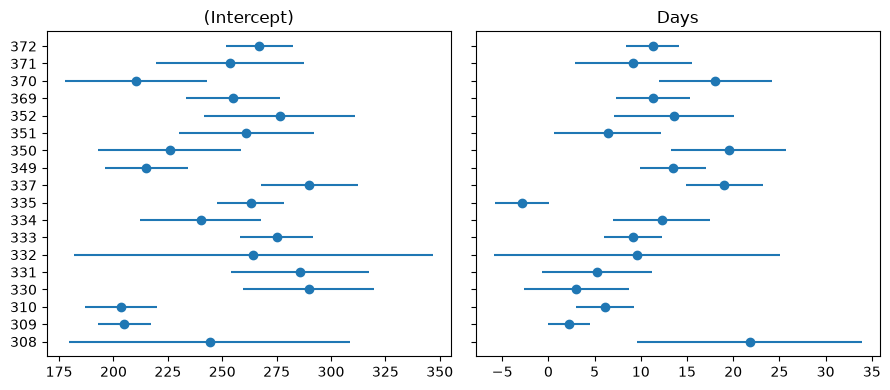

In [26]:
fm_plm = lmList("Reaction ~ Days | Subject", sleepstudy)
cf = fm_plm.coef()
print("pooled sigma:", fm_plm.sigma())
ci = fm_plm.confint()
fig, ax = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
y = np.arange(len(cf))
for j, nm in enumerate(cf.columns):
    lo, hi = ci[nm].iloc[:, 0], ci[nm].iloc[:, 1]
    ax[j].hlines(y, lo, hi); ax[j].plot(cf[nm], y, "o")
    ax[j].set_title(nm)
ax[0].set_yticks(y, cf.index)
plt.tight_layout()
cf.head()

### Check against R

In [27]:
assert list(cf.index) == ref["plm_subjects"]
assert_allclose(cf.values.ravel(order="F"), ref["plm_coef"], rtol=1e-10)
assert_allclose(fm_plm.sigma(), ref["plm_sigma"], rtol=1e-10)
# R's confint.lmList4: array subject x (2.5 %, 97.5 %) x coefficient
ours = np.stack([ci[nm].values for nm in cf.columns], axis=2)
assert_allclose(ours.ravel(order="F"), ref["plm_ci"], rtol=1e-10)
fm_2 = fm_plm.update(pool=False)
assert_allclose(fm_2.coef().values.ravel(order="F"), ref["plm2_coef"], rtol=1e-10)
print("lmList agrees with R")

lmList agrees with R


## 9. Influence: deleting one subject at a time

`influence(fm1, "Subject")` refits the model without each subject (starting from the full
fit); Cook's distance summarizes the change in the fixed effects, `dfbeta`/`dfbetas` give
the change per coefficient, and `dfbeta(which="var.cov")` the change in the
variance-covariance parameters. `hatvalues` and the observation-level `cooks_distance` use the
hat matrix of the fitted model.

,(Intercept),Days,cooks
309,0.410875,0.309897,0.132021
335,-0.094985,0.555956,0.115094
337,-0.333587,-0.324775,0.111997
310,0.427609,0.158341,0.098241
308,0.058725,-0.448927,0.082148


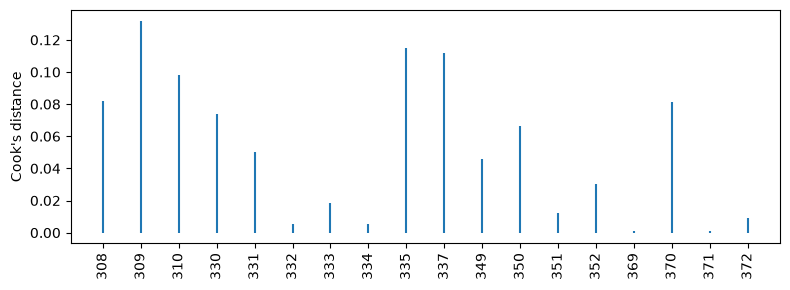

In [28]:
inf_fm1 = influence(fm1R, "Subject")
cd = inf_fm1.cooks_distance()
fig, ax = plt.subplots(figsize=(8, 3))
ax.vlines(range(len(cd)), 0, np.asarray(cd)); ax.set_xticks(range(len(cd)), cf.index, rotation=90)
ax.set_ylabel("Cook's distance"); plt.tight_layout()
pd.DataFrame(inf_fm1.dfbetas()).assign(cooks=np.asarray(cd)).sort_values("cooks", ascending=False).head()

In [29]:
hat = fm1R.hatvalues()
cooks_obs = lme4.cooks_distance(fm1R)
print("sum of hat values (effective number of parameters):", hat.sum())
pd.Series(np.asarray(cooks_obs)).describe()

sum of hat values (effective number of parameters): 29.022123950112864


count    180.000000
mean       0.111237
std        0.391939
min        0.000008
25%        0.007475
50%        0.024148
75%        0.077698
max        4.332164
dtype: float64

### Check against R

In [30]:
assert_allclose(np.asarray(cd), ref["inf_cooks"], rtol=1e-4)
assert_allclose(np.asarray(inf_fm1.dfbeta()).ravel(order="F"), ref["inf_dfbeta"], rtol=1e-4, atol=1e-6)
assert_allclose(np.asarray(inf_fm1.dfbetas()).ravel(order="F"), ref["inf_dfbetas"], rtol=1e-4, atol=1e-6)
assert_allclose(np.asarray(inf_fm1.dfbeta(which="var.cov")).ravel(order="F"), ref["inf_varcov"],
                rtol=5e-3, atol=1e-3)
assert_allclose(np.asarray(hat), ref["hat"], rtol=1e-6)
assert_allclose(np.asarray(cooks_obs), ref["cooks_obs"], rtol=1e-5)
print("influence diagnostics agree with R")

influence diagnostics agree with R


The deletion refits stop after at most `maxfun=1000` evaluations from the full-data optimum;
the refitted estimates are compared at 1e-4 (the variance-covariance parameters, which
move along flatter directions, at 5e-3).

## 10. Residual checks

Scaled Pearson residuals against fitted values, and a normal quantile plot (R's
`plot(fm1)` and `qqmath(fm1)`, here from `lme4.plots`):

[-3.95356735 -0.46339768  0.02311766  0.46340208  5.17926037]


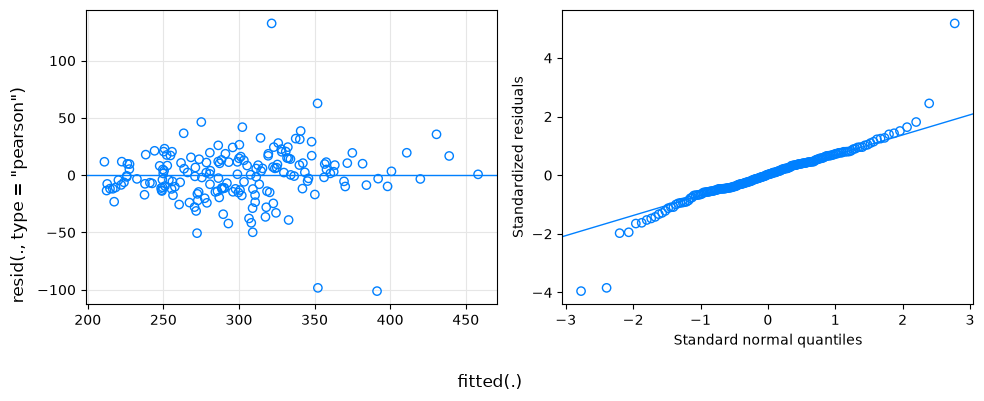

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_merMod(fm1R, ax=ax[0])
qqmath_merMod(fm1R, ax=ax[1])
plt.tight_layout()
res_sc = fm1R.residuals(type="pearson", scaled=True)
print(np.quantile(fm1R.residuals(scaled=True), [0, .25, .5, .75, 1]))

### Check against R

In [32]:
assert_allclose(np.asarray(fm1R.residuals()), ref["res_resp"], rtol=1e-6, atol=1e-6)
assert_allclose(np.asarray(res_sc), ref["res_pearson_scaled"], rtol=1e-6, atol=1e-7)
assert_allclose(np.asarray(fm1R.fitted()), ref["fitted"], rtol=1e-8)
assert_allclose(np.quantile(fm1R.residuals(scaled=True), [0, .25, .5, .75, 1]),
                ref["res_quantiles"], rtol=1e-6)
assert_allclose(fm1R.ranef(condVar=False)["Subject"].values.ravel(order="F"),
                ref["ranef_Subject"], rtol=1e-5, atol=1e-6)
print("residuals agree with R")

residuals agree with R


## Summary

| quantity | agreement with R |
|---|---|
| `us`/`cs`/`diag`/`ar1` fits: logLik, AIC | rtol 1e-8 |
| estimates, `par`, `theta`, `sigma`, `VarCorr` (printed, line by line) | rtol 1e-6 (1e-4 for heterogeneous 10-dim `cs`) |
| vignette `summary()` of a `cs()` model | identical text |
| `isSingular`, `rePCA` (singular values; rotations up to sign) | rtol 1e-6; singular `cake` fit 1e-3 |
| convergence: derivatives, tight tolerances, restarts, rescaling | gradient atol 1e-5, Hessian 1e-4, fits 1e-6 |
| quadratic-slope model with a convergence warning | both warn; Python's logLik 0.003 higher (flat surface) |
| `autoscale` | fixef 1e-5, vcov 5e-4 (depends on theta), warning text identical |
| `allFit` (5 optimizers) | logLik 1e-8, estimates 1e-4 |
| `lmList` coefficients and confidence intervals | rtol 1e-10 |
| `influence` (Cook's distance, dfbeta(s)), `hatvalues`, residuals | 1e-4 / 1e-6 |